# Dual-encoder reranking: MIST-style spectrum encoder × molecular GNN

**ECSE 552 project — Mohammed's part (branch `mo_graph`).**

**Task** (Kaggle *Enveda CASMI 2026*): given the MS/MS spectra of an unknown molecule, rank candidate structures so
that the true one comes first. Score: MRR@25 on the InChIKey first block.

The team's earlier results (Milton's recap) set the bar:

| Method (full catalog, 8,068 val spectra) | MRR@25 |
|---|---:|
| Mass only | 0.336 |
| DeepSets fingerprint likelihood | 0.266 |
| Graph reranker pilot (800 spectra, on DeepSets top-50) | 0.292 |

Two weaknesses stood out:

1. The fingerprint model ignores the molecular formula, so it cannot beat mass alone.
2. The pilot reranker only saw the fingerprint top-50, losing 119 of 800 correct answers before reranking.

**This notebook builds a dual-input reranker** (proposal, Architecture 2):

1. **Spectrum encoder = MIST** (Goldman et al., *Nat. Mach. Intell.* 2023). Each peak is annotated with a
   subformula of the *candidate's* formula. A transformer with pairwise formula-difference attention then encodes
   the set of formulae. It also predicts a 1,024-bit Morgan fingerprint, the same target as Antoine's DeepSets.
2. **Graph encoder = GINE message-passing network** (Xu et al. 2019; Hu et al. 2020) over RDKit atom/bond graphs.
3. **Matching head** combines both embeddings with mass error, formula-explained intensity and the fingerprint
   likelihood. It is trained with a listwise ranking loss against mass- and formula-matched hard negatives, as in
   JESTR (Kalia et al., *Bioinformatics* 2025).

Every candidate in the 10 ppm mass window is scored, so nothing is lost to a shortlist. No ground-truth formula is
used at inference.

**Why re-implement MIST instead of using the released checkpoint?** The public weights (Zenodo 8316682):

* were trained on NPLIB1 for `[M+H]+` only;
* need Python 3.8, PyTorch 1.9 and Lightning 1.6 on Linux;
* predict 4,096-bit fingerprints.

CASMI26 has 20+ adducts, so we keep MIST's two key ideas (subformula tokens, pairwise formula-difference attention)
and train them on our own split.

**Code layout.** Model, chemistry and scoring code live in `mo_graph/dualrerank.py` (imported as `dr`). The offline
Kaggle notebook in `mo_graph/kaggle/` imports the same module. This notebook holds the data splits, training,
evaluation and figures.

## 0. Setup

Data, both folders git-ignored:

* the Kaggle files (`train.parquet`, `test.parquet`, `sample_submission.csv`) in
  `data/enveda-CASMI26-molecule-id-mass-spectra/`, Antoine's `config.DATA_PATH`;
* Milton's recap files in `data/recap/`: his validation queries and his DeepSets checkpoint.

In [1]:
import hashlib, json, math, os, shutil, sys, time, warnings
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw

warnings.filterwarnings("ignore", category=UserWarning)

REPO = Path.cwd().resolve()
if not (REPO / "config.py").exists():
    REPO = REPO.parent
OUT = REPO / "mo_graph"
sys.path[:0] = [str(REPO), str(OUT)]
import config as team_config            # Antoine's config: ADDUCTS, fingerprint settings, data path
from streamingDataset import get_split  # Antoine's structure-level train/val hash
import dualrerank as dr                 # our model / chemistry / scoring code

DATA = REPO / "data" / "recap"
KAGGLE = REPO / Path(team_config.DATA_PATH).parent
TRAIN_PQ = KAGGLE / "train.parquet"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = OUT / "results"; RES.mkdir(parents=True, exist_ok=True)
CKPT = OUT / "checkpoints"; CKPT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # On Windows the NVIDIA driver silently spills CUDA allocations into system RAM ("sysmem fallback") instead of
    # raising out-of-memory; PyTorch's cache then grows into shared memory and training slows ~8x. Capping the
    # process below the card's size makes the caching allocator recycle blocks instead.
    torch.cuda.set_per_process_memory_fraction(0.85)
QUICK = os.environ.get("QUICK", "0") == "1"     # QUICK=1 -> small smoke-test run (CPU friendly)
RETRAIN = os.environ.get("RETRAIN", "0") == "1" # default: reuse checkpoints in mo_graph/checkpoints if present


def log(msg):
    """Print and append to mo_graph/train_log.txt (a notebook run only shows its output at the end)."""
    print(msg)
    with open(OUT / "train_log.txt", "a", encoding="utf-8") as fh:
        fh.write(f"{time.strftime('%H:%M:%S')} {msg}\n")


MODEL_CFG = dict(d=256, heads=8, spec_layers=3, gnn_layers=4, dropout=0.1, fp_bits=team_config.FINGERPRINT_SIZE)
CFG = dict(
    seed=42,
    ppm=10.0,                    # precursor mass window, same as Antoine/Milton
    fp_radius=team_config.FINGERPRINT_RADIUS,
    max_peaks=64,                # MIST keeps ~50 annotated formulae; we keep the 64 most intense peaks
    annot_ppm=20.0, annot_abs=0.002,   # subformula tolerance (MIST: 20 ppm)
    neg_per_query=15, max_neg_formulas=3, max_other_formulas=5, cand_cap=31,
    batch_queries=32, epochs=4 if not QUICK else 2, lr=3e-4, weight_decay=1e-4, fp_weight=1.0,
    train_limit=120_000 if not QUICK else 6000, eval_limit=None if not QUICK else 800,
    max_precursor_ppm=10.0,      # drop training spectra whose labelled structure does not match the precursor
)
torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = {"Mass only": "#9e9e9e", "DeepSets FP": "#8fb3d9", "MIST FP": "#2f6fb0",
          "Dual (no GNN)": "#f2a65a", "Dual MIST+GNN": "#c4462d"}
METHODS = list(COLORS)
print(f"device={DEVICE}  quick={QUICK}  torch={torch.__version__}")

Using device: cuda
device=cuda  quick=False  torch=2.11.0+cu128


## 1. Chemistry: adducts and MIST-style subformula annotation

**Adducts.** The parser (`dr.parse_adduct`) is generic (`[nM ± groups]z±`); the cell checks that it reproduces
Antoine's hand-written `config.ADDUCTS` table. Neutral mass = `(|z|·m/z − offset) / n`, as in his `get_neutral_mass`.

**Annotation.** For a hypothesised precursor formula $F$, we:

1. enumerate every subformula $f \le F$;
2. drop chemically impossible ones (ring-plus-double-bond equivalent < −0.5);
3. give each peak the subformula whose ion mass is closest within 20 ppm (2 mDa floor).

A peak is then represented by *which atoms it contains* ($f$) and *which atoms were lost* ($F - f$). This is the
representation MIST's transformer works on.

Generic adduct parser reproduces all 22 entries of config.ADDUCTS


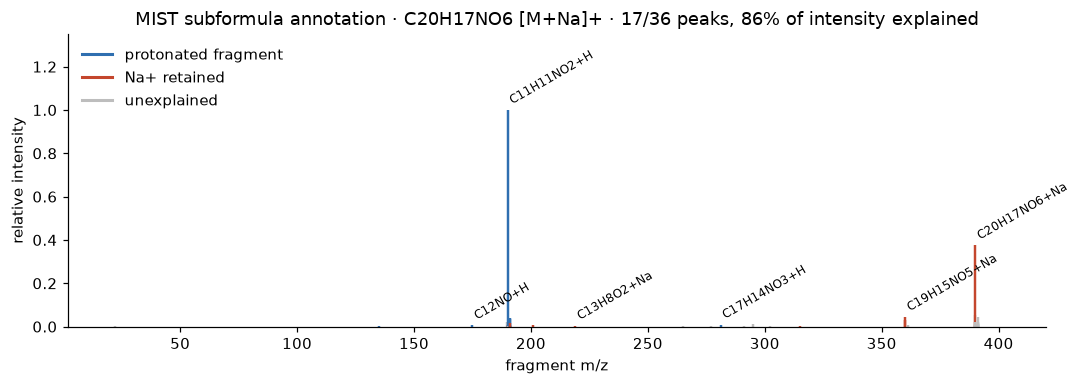

In [2]:
for name, (n, z, off) in team_config.ADDUCTS.items():
    pn, pz, poff, _ = dr.parse_adduct(name)
    assert (pn, pz) == (n, z) and abs(poff - off) < 2e-3, name
print(f"Generic adduct parser reproduces all {len(team_config.ADDUCTS)} entries of config.ADDUCTS")

ex = pd.read_parquet(DATA / "example_spectra.parquet")
ex = ex[(ex.inchikey14 == "IYGYMKDQCDOMRE") & (ex.adduct == "[M+Na]+")].iloc[0]
emz, eint = np.asarray(ex.ms2_mzs), np.asarray(ex.ms2_normalized_intensities)
esub, _, etyp = dr.annotate(emz, dr.parse_adduct("[M+Na]+")[3], dr.formula_vector(ex.molecular_formula))
fstr = lambda v: "".join(f"{e}{'' if n == 1 else n}" for e, n in zip(dr.ELEMS, v) if n)

fig, ax = plt.subplots(figsize=(10, 3.6))
cols = {0: "#bdbdbd", 1: "#2f6fb0", 2: "#c4462d", 3: "#6a3d9a"}
for m, i, t in zip(emz, eint, etyp):
    ax.vlines(m, 0, i, color=cols[int(t)], lw=1.6)
labelled = []
for k in np.argsort(-eint):
    if etyp[k] and all(abs(emz[k] - m) > 12 for m in labelled) and len(labelled) < 6:
        ax.annotate(f"{fstr(esub[k])}{'+H' if etyp[k] == 1 else '+Na'}", (emz[k], eint[k]), xytext=(0, 4),
                    textcoords="offset points", ha="left", fontsize=8, rotation=30)
        labelled.append(emz[k])
ax.set_xlim(emz.min() - 20, ex.precursor_mz + 30)
ax.set(xlabel="fragment m/z", ylabel="relative intensity", ylim=(0, 1.35),
       title=f"MIST subformula annotation · {ex.molecular_formula} [M+Na]+ · "
             f"{(etyp > 0).sum()}/{len(etyp)} peaks, {eint[etyp > 0].sum() / eint.sum():.0%} of intensity explained")
ax.legend(handles=[plt.Line2D([], [], color=cols[c], lw=2, label=l) for c, l in
                   [(1, "protonated fragment"), (2, "Na+ retained"), (0, "unexplained")]], frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "01_subformula_annotation.png", dpi=200); plt.show()

## 2. Data: structure-disjoint splits and candidate catalog

**Held-out structures.** These never enter training, not even as negatives:

* Milton's validation structures, so his 8,068-spectrum benchmark stays comparable;
* Antoine's validation hash (`streamingDataset.get_split`);
* all 250 `enveda-np-examples` natural products. Kaggle calls this the library closest to the hidden test set (same
  timsTOF, same pipeline). Their spectra in other libraries are excluded too.

**Training spectra.** One spectrum per remaining structure (structural diversity matters most for the GNN),
restricted to:

* the ten adducts of the hidden test set;
* precursor error ≤ 10 ppm — some library labels are thousands of ppm off;
* at least 3 peaks.

Structures measured outside `enveda-180` (natural-product-rich libraries, closer to the test set) are taken first,
up to the compute budget. 5% of training structures form the *tune* set used for model selection.

**Test sets.**

1. `test_val`: Milton's 8,068 validation spectra, scored per spectrum (his benchmark).
2. `test_np`: the 250 `enveda-np-examples` molecules, scored **per molecule** after combining all their spectra
   (the Kaggle protocol).

In [3]:
TEST_ADDUCTS = ["[M+H]+", "[M+NH4]+", "[M-H2O+H]+", "[M-2H2O+H]+", "[M+Na]+", "[M+K]+",
                "[M-H]-", "[M-H2O-H]-", "[M+CH2O2-H]-", "[M+Cl]-"]
SPEC_COLS = ["ms2_mzs", "ms2_normalized_intensities", "collision_energy_ev"]
t0 = time.time()
meta = pq.read_table(TRAIN_PQ, columns=["ingest_lib", "normalized_smiles", "inchikey14", "adduct", "precursor_mz",
                                        "precursor_error_ppm", "num_peaks"]).to_pandas()
milton = pd.read_parquet(DATA / "deepsets_v1_sample.parquet")
np_ik = set(meta.loc[meta.ingest_lib == "enveda-np-examples", "inchikey14"])
antoine_val = {ik for ik in meta.inchikey14.unique() if get_split(ik) == "val"}
held_out = set(milton.loc[milton.split == "val", "inchikey14"]) | antoine_val | np_ik
print(f"train.parquet: {len(meta):,} spectra, {meta.inchikey14.nunique():,} structures")
print(f"held out: {len(held_out):,} structures (Antoine val {len(antoine_val):,}, enveda-np-examples {len(np_ik)})")


def in_tune(ik):  # 5% of training structures; residue 1 never overlaps Antoine's val (residue 0 mod 10)
    return int.from_bytes(hashlib.blake2b(str(ik).encode(), digest_size=8).digest(), "big") % 20 == 1


ok = (~meta.inchikey14.isin(held_out) & meta.adduct.isin(TEST_ADDUCTS) & (meta.num_peaks >= 3)
      & (meta.precursor_error_ppm.abs() <= CFG["max_precursor_ppm"]))
rows = meta[ok].sample(frac=1.0, random_state=CFG["seed"]).drop_duplicates("inchikey14")   # 1 spectrum / structure
rows = rows.assign(split2=np.where(rows.inchikey14.map(in_tune), "tune", "train"))
np_like = set(meta.loc[meta.ingest_lib != "enveda-180", "inchikey14"])
tr = rows[rows.split2 == "train"]
tr = pd.concat([tr[tr.inchikey14.isin(np_like)], tr[~tr.inchikey14.isin(np_like)]]).head(CFG["train_limit"])
take = pd.concat([tr, rows[rows.split2 == "tune"].sample(400 if QUICK else 1500, random_state=0),
                  meta[meta.ingest_lib == "enveda-np-examples"].assign(split2="test_np")])
print(f"training structures: {len(tr):,} ({tr.inchikey14.isin(np_like).mean():.0%} also measured outside enveda-180)")

# peak lists of the selected rows, in one streaming pass over the 3 GB file
want, got, off = np.sort(take.index.values), {}, 0
for batch in pq.ParquetFile(TRAIN_PQ).iter_batches(batch_size=65536, columns=SPEC_COLS):
    lo_i, hi_i = np.searchsorted(want, [off, off + batch.num_rows])
    if hi_i > lo_i:
        sel = batch.take(want[lo_i:hi_i] - off).to_pydict()
        for j, r in enumerate(want[lo_i:hi_i]):
            got[r] = [sel[c][j] for c in SPEC_COLS]
    off += batch.num_rows
for k, c in enumerate(SPEC_COLS):
    take[c] = [got[r][k] for r in take.index]

test_val = milton[milton.split == "val"].assign(split2="test_val")
if CFG["eval_limit"]:
    test_val = test_val.sample(CFG["eval_limit"], random_state=0)
cols = ["split2", "inchikey14", "normalized_smiles", "ingest_lib", "adduct", "precursor_mz"] + SPEC_COLS
queries = pd.concat([take[cols], test_val[cols]], ignore_index=True)   # one row per query spectrum
print(f"data prepared in {time.time() - t0:.0f}s")

train.parquet: 2,539,608 spectra, 275,810 structures
held out: 32,466 structures (Antoine val 27,773, enveda-np-examples 250)


training structures: 120,000 (62% also measured outside enveda-180)


data prepared in 16s


In [4]:
# Candidate catalog: every training structure, featurised once with RDKit (graph + fingerprint + formula), cached
cat_df = meta.drop_duplicates("inchikey14")
CAT_DIR = OUT / "cache" / f"catalog_{len(cat_df)}"
if (CAT_DIR / "catalog_arrays.npz").exists():
    G = dr.load_catalog(CAT_DIR)
else:
    t0 = time.time()
    G = dr.featurize_catalog(cat_df.inchikey14.values, cat_df.normalized_smiles.values, MODEL_CFG["fp_bits"], CFG["fp_radius"])
    dr.save_catalog(G, CAT_DIR)
    print(f"featurised {len(G['mass']):,} molecules in {time.time() - t0:.0f}s")
cat = dr.Catalog(G, DEVICE)
print(f"Catalog: {cat.N:,} structures, {len(cat.formulas):,} distinct formulas")

queries["cat_idx"] = queries.inchikey14.map(cat.index)
queries = queries[queries.cat_idx.notna()].reset_index(drop=True)
queries["cat_idx"] = queries.cat_idx.astype(int)
ADDUCT_VOCAB = ["<UNK>"] + queries.loc[queries.split2 == "train", "adduct"].value_counts().index[:30].tolist()
sp = dr.Spectra(queries, ADDUCT_VOCAB, CFG["max_peaks"])
queries["neutral"] = sp.neutral
TRUE_FID = cat.fid[queries.cat_idx.values]
scorer = dr.Scorer(cat, sp, CFG["ppm"], CFG["annot_ppm"], CFG["annot_abs"])
display(queries.groupby("split2").agg(spectra=("inchikey14", "size"), structures=("inchikey14", "nunique"),
                                       adduct_parsed=("neutral", lambda x: x.notna().mean())).round(3))
for a, b in [("train", "tune"), ("train", "test_val"), ("train", "test_np"), ("tune", "test_val"), ("tune", "test_np")]:
    assert set(queries.loc[queries.split2 == a, "inchikey14"]).isdisjoint(queries.loc[queries.split2 == b, "inchikey14"])
print(f"Splits are structure-disjoint (InChIKey first block); median peaks kept {np.median(sp.NPK):.0f}")

Catalog: 275,810 structures, 51,196 distinct formulas


,spectra,structures,adduct_parsed
split2,,,
test_np,1184,250,1.0
test_val,8068,4930,1.0
train,120000,120000,1.0
tune,1500,1500,1.0


Splits are structure-disjoint (InChIKey first block); median peaks kept 57


## 3. Candidate pools and training lists

* **Evaluation pool** of a spectrum: every catalog structure within 10 ppm of the neutral mass implied by the
  precursor m/z and adduct (the team's mass filter, no shortlist).
* **Training list** of a spectrum: the true structure plus hard negatives, in this order:
  1. same-formula isomers (only connectivity can separate them);
  2. other formulas from the same mass window (at most 5);
  3. nearest-mass structures, if the window is small.

120,000 training spectra, mean list length 22.0


Test candidate recall (true structure inside the 10 ppm pool): 94.91%


,count,mean,std,min,25%,50%,75%,90%,max
pool,8068.0,56.8,75.3,0.0,6.0,25.0,80.0,160.0,501.0
isomers,8068.0,31.4,58.2,0.0,2.0,8.0,30.0,95.0,477.0
formulas,8068.0,4.1,3.1,0.0,1.0,3.0,6.0,9.0,16.0


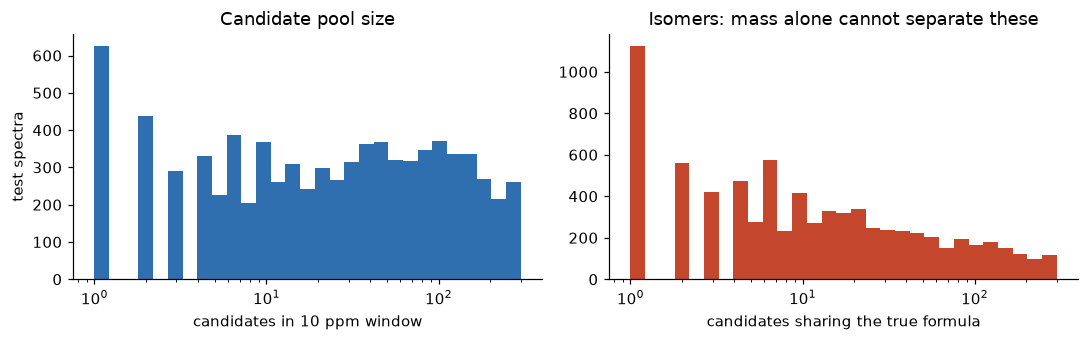

annotating training pairs for 120,000 spectra


annotated 540,985 (spectrum, formula) pairs in 131s; with the true formula the annotation explains a median 97% of spectral intensity


In [5]:
is_held_out = np.array([ik in held_out for ik in cat.ik14])
rng = np.random.default_rng(CFG["seed"])


def train_list(q):
    true_i, nm = queries.at[q, "cat_idx"], queries.at[q, "neutral"]
    lo, hi = cat.window(nm, CFG["ppm"])
    pool = [i for i in range(lo, hi) if i != true_i and not is_held_out[i]]
    iso = [i for i in pool if cat.fid[i] == TRUE_FID[q]]
    other = [i for i in pool if cat.fid[i] != TRUE_FID[q]]
    rng.shuffle(iso); rng.shuffle(other)
    keep_f = set(list(dict.fromkeys(cat.fid[i] for i in other))[:CFG["max_other_formulas"]])
    other = [i for i in other if cat.fid[i] in keep_f]
    negs = iso[:16] + other[:CFG["cand_cap"] - min(len(iso), 16)]
    if len(negs) < CFG["neg_per_query"]:
        lo2, hi2 = max(0, lo - 24), min(cat.N, hi + 24)
        near = sorted((i for i in range(lo2, hi2) if not lo <= i < hi and not is_held_out[i]), key=lambda i: abs(cat.mass[i] - nm))
        keep_f = list(dict.fromkeys(cat.fid[i] for i in near))[:CFG["max_neg_formulas"]]
        negs += [i for i in near if cat.fid[i] in keep_f][:CFG["neg_per_query"] - len(negs)]
    return [true_i] + negs


fit_q = np.where((queries.split2 == "train") & queries.neutral.notna())[0]
tune_q = np.where(queries.split2 == "tune")[0]
test_q = np.where(queries.split2 == "test_val")[0]
np_q = np.where(queries.split2 == "test_np")[0]
TRAIN_LISTS = {q: train_list(q) for q in fit_q}
print(f"{len(fit_q):,} training spectra, mean list length {np.mean([len(v) for v in TRAIN_LISTS.values()]):.1f}")

pool_stats = []
for q in test_q:
    p = scorer.own_pool(q)
    pool_stats.append(dict(pool=len(p), isomers=int((cat.fid[p] == TRUE_FID[q]).sum()), formulas=len(set(cat.fid[p])),
                           covered=queries.at[q, "cat_idx"] in set(p)))
pool_stats = pd.DataFrame(pool_stats)
print(f"Test candidate recall (true structure inside the 10 ppm pool): {pool_stats.covered.mean():.2%}")
display(pool_stats[["pool", "isomers", "formulas"]].describe(percentiles=[.25, .5, .75, .9]).T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(np.clip(pool_stats.pool, 1, 300), bins=np.logspace(0, np.log10(300), 30), color="#2f6fb0")
axes[0].set(xscale="log", xlabel="candidates in 10 ppm window", ylabel="test spectra", title="Candidate pool size")
axes[1].hist(np.clip(pool_stats.loc[pool_stats.covered, "isomers"], 1, 300), bins=np.logspace(0, np.log10(300), 30), color="#c4462d")
axes[1].set(xscale="log", xlabel="candidates sharing the true formula", title="Isomers: mass alone cannot separate these")
fig.tight_layout(); fig.savefig(FIG / "02_candidate_pools.png", dpi=200); plt.show()

t0 = time.time()
log(f"annotating training pairs for {len(fit_q):,} spectra")
TRAIN_PAIRS = scorer.build_pairs([(q, cat.fid[i]) for q, lst in TRAIN_LISTS.items() for i in lst])
idx, _, _, TYP = TRAIN_PAIRS
expl_true = [(sp.INT[q] * (TYP[idx[(q, TRUE_FID[q])]] > 0)).sum() / max(sp.INT[q].sum(), 1e-9) for q in fit_q]
print(f"annotated {len(idx):,} (spectrum, formula) pairs in {time.time() - t0:.0f}s; with the true formula the "
      f"annotation explains a median {np.median(expl_true):.0%} of spectral intensity")

## 4. Model (`dr.DualReranker`)

* `dr.MISTEncoder`: precursor token + one token per peak, 3 transformer layers whose attention logits get a learned
  bias from pairwise formula differences; outputs the spectrum embedding and fingerprint logits.
* `dr.GraphEncoder`: 4 GINE layers (edge-aware GIN) over atom/bond embeddings, mean ‖ max pooling.
* Matching MLP on `[z_s ⊙ z_g, |z_s − z_g|, cos]`, ppm error, explained intensity, annotated fraction and the
  fingerprint log-likelihood, plus a learnable Gaussian mass-error prior. `use_graph=False` gives the ablation.

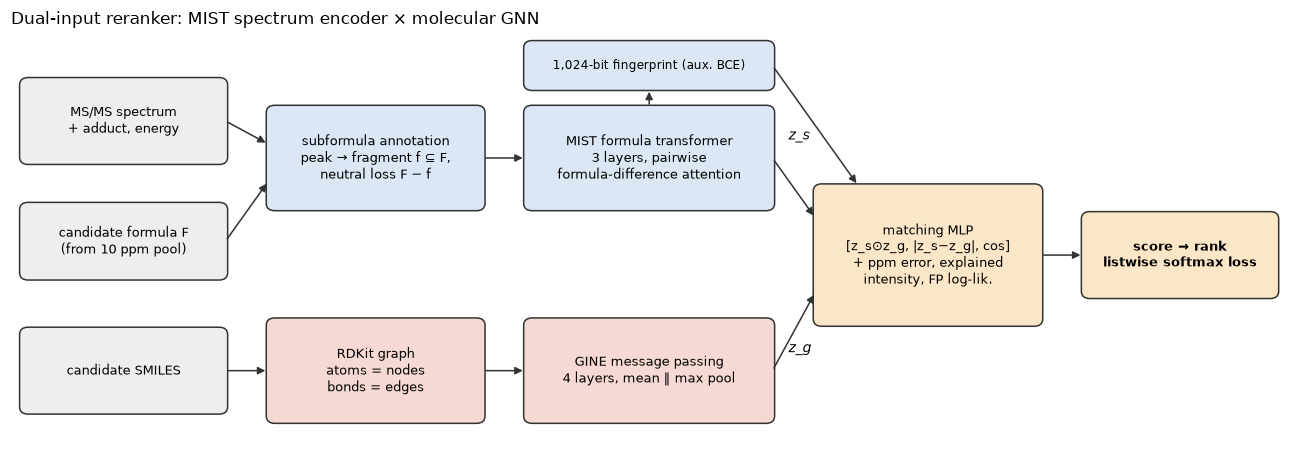

In [6]:
def box(ax, xy, w, h, text, fc, fs=8.5, bold=False):
    ax.add_patch(plt.matplotlib.patches.FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="#333333", lw=1))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center", fontsize=fs, weight="bold" if bold else "normal")


fig, ax = plt.subplots(figsize=(12, 4.2)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.4); ax.axis("off")
blue, red, grey, gold = "#dbe7f4", "#f6d9d2", "#eeeeee", "#fbe6c8"
box(ax, (0.1, 3.0), 1.9, 0.9, "MS/MS spectrum\n+ adduct, energy", grey)
box(ax, (0.1, 1.75), 1.9, 0.8, "candidate formula F\n(from 10 ppm pool)", grey)
box(ax, (2.4, 2.5), 2.0, 1.1, "subformula annotation\npeak → fragment f ⊆ F,\nneutral loss F − f", blue)
box(ax, (4.8, 2.5), 2.3, 1.1, "MIST formula transformer\n3 layers, pairwise\nformula-difference attention", blue)
box(ax, (4.8, 3.8), 2.3, 0.5, "1,024-bit fingerprint (aux. BCE)", blue, fs=8)
box(ax, (0.1, 0.3), 1.9, 0.9, "candidate SMILES", grey)
box(ax, (2.4, 0.2), 2.0, 1.1, "RDKit graph\natoms = nodes\nbonds = edges", red)
box(ax, (4.8, 0.2), 2.3, 1.1, "GINE message passing\n4 layers, mean ‖ max pool", red)
box(ax, (7.5, 1.25), 2.1, 1.5, "matching MLP\n[z_s⊙z_g, |z_s−z_g|, cos]\n+ ppm error, explained\nintensity, FP log-lik.", gold)
box(ax, (10.0, 1.55), 1.8, 0.9, "score → rank\nlistwise softmax loss", gold, bold=True)
for a, b in [((2.0, 3.45), (2.4, 3.2)), ((2.0, 2.15), (2.4, 2.8)), ((4.4, 3.05), (4.8, 3.05)), ((5.95, 3.6), (5.95, 3.8)),
             ((2.0, 0.75), (2.4, 0.75)), ((4.4, 0.75), (4.8, 0.75)), ((7.1, 3.05), (7.5, 2.4)), ((7.1, 0.75), (7.5, 1.6)),
             ((7.1, 4.05), (7.9, 2.75)), ((9.6, 2.0), (10.0, 2.0))]:
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1))
ax.text(7.25, 3.25, "z_s", fontsize=9, style="italic"); ax.text(7.25, 0.95, "z_g", fontsize=9, style="italic")
ax.set_title("Dual-input reranker: MIST spectrum encoder × molecular GNN", fontsize=11, loc="left")
fig.tight_layout(); fig.savefig(FIG / "00_architecture.png", dpi=200); plt.show()

## 5. Evaluation protocol (identical for every method)

We report Top-1, Top-5 and MRR@25 with **expected rank under ties** (`dr.tie_metrics`, Milton's convention). For
example, a structure tied with one competitor for first place gets reciprocal rank 0.75. A query whose true structure
is not in the pool scores zero for every method.

Baselines, all scored on the same pools:

* **Mass only**: precursor mass error.
* **DeepSets FP**: Milton's trained checkpoint, fingerprint likelihood.
* **MIST FP**: our encoder's fingerprint head alone (MIST-style retrieval).
* **Dual (no GNN)**: the full model with the graph branch removed.

In [7]:
class SpectrumDeepSets(nn.Module):   # Milton's DeepSets (class + preprocessing copied from his recap notebook)
    def __init__(self, n_adducts, fp_bits=1024):
        super().__init__()
        self.n_adducts = n_adducts
        self.peak_encoder = nn.Sequential(nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU())
        self.predictor = nn.Sequential(nn.Linear(256 + 5 + n_adducts, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, fp_bits))

    def forward(self, peaks, mask, metadata, adducts):
        h = self.peak_encoder(peaks); valid = mask.unsqueeze(-1)
        mean = (h * valid).sum(1) / valid.sum(1).clamp(min=1)
        mx = torch.where(mask.any(1, keepdim=True), h.masked_fill(~valid, -1e9).amax(1), 0.0)
        ion = F.one_hot(adducts, num_classes=self.n_adducts).float()
        return self.predictor(torch.cat([mean, mx, metadata, ion], 1))


ds_ckpt = torch.load(DATA / "models" / "deepsets_fp_v1.pt", map_location="cpu", weights_only=True)
deepsets = SpectrumDeepSets(len(ds_ckpt["adduct_names"]), ds_ckpt["fp_bits"]).to(DEVICE).eval()
deepsets.load_state_dict(ds_ckpt["model_state"])
DS_ADDUCT = {a: i for i, a in enumerate(ds_ckpt["adduct_names"])}


@torch.no_grad()
def deepsets_scores(items):
    """Milton's fingerprint log-likelihood for each (q, pool) item."""
    out = []
    for q, p in items:
        r = queries.iloc[q]
        mz, it = np.asarray(r.ms2_mzs, float), np.asarray(r.ms2_normalized_intensities, float)
        n = min(len(mz), len(it)); mz, it = mz[:n], it[:n]
        ok = np.isfinite(mz) & np.isfinite(it) & (mz > 0) & (it > 0); mz, it = mz[ok], it[ok]
        keep = np.argsort(it)[-128:]; mz, it = mz[keep], it[keep]
        pk = torch.tensor(np.column_stack([mz / 1000, np.sqrt(it), (r.precursor_mz - mz) / 1000]), dtype=torch.float32)[None]
        e = sp.energy[q]
        meta_ = torch.tensor([[r.precursor_mz / 1000, np.log1p(r.precursor_mz) / 8, 0 if np.isnan(e) else e / 80,
                               sp.n_energies[q] / 4, float(not np.isnan(e))]], dtype=torch.float32)
        pr = torch.sigmoid(deepsets(pk.to(DEVICE), torch.ones(pk.shape[:2], dtype=torch.bool, device=DEVICE),
                                    meta_.to(DEVICE), torch.tensor([DS_ADDUCT.get(r.adduct, 0)], device=DEVICE)))[0]
        pr = pr.clamp(1e-6, 1 - 1e-6); y = cat.unpack_fp(p)
        out.append((y * torch.log(pr) + (1 - y) * torch.log(1 - pr)).sum(1).cpu().numpy())
    return out


def score_with_baselines(model, items, with_baselines, zg):
    scored = scorer.score_pools(model, items, zg)
    if not with_baselines:
        return [{model.name: d[model.name]} for d in scored]
    for d, ds in zip(scored, deepsets_scores(items)):
        d["DeepSets FP"] = ds
    return scored


def evaluate(model, qs, with_baselines=False):
    """Per-spectrum evaluation: each spectrum ranks its own 10 ppm pool."""
    rows, live = [], []
    for q in qs:
        p = scorer.own_pool(q)
        if queries.at[q, "cat_idx"] in set(p):
            live.append((q, p))
        else:
            rows.append(dict(q=q, pool=len(p), covered=False))
    need = np.unique(np.concatenate([p for _, p in live])) if live else np.arange(0)
    zg = scorer.embed_catalog(model, ids=need) if model.use_graph else None   # only graphs that occur in a pool
    for (q, p), d in zip(live, score_with_baselines(model, live, with_baselines, zg)):
        tpos = int(np.where(p == queries.at[q, "cat_idx"])[0][0])
        r = dict(q=q, pool=len(p), covered=True, isomers=int((cat.fid[p] == TRUE_FID[q]).sum()))
        for m, sc in d.items():
            r.update({f"{m}_{k}": v for k, v in dr.tie_metrics(sc, tpos).items()})
        rows.append(r)
    return pd.DataFrame(rows).sort_values("q").reset_index(drop=True)


def evaluate_molecules(model, qs, with_baselines=False):
    """Per-molecule evaluation (Kaggle protocol): all spectra of a molecule rank one shared pool.
    Reports the aggregated ranking and the average single-spectrum ranking ('_single')."""
    mols = pd.Series(qs).groupby(queries.inchikey14.values[qs]).apply(list)
    zg = scorer.embed_catalog(model, ids=np.unique(np.concatenate([scorer.molecule_pool(mq) for mq in mols])))         if model.use_graph else None
    rows = []
    for mol, mq in mols.items():
        p = scorer.molecule_pool(mq); true_i = queries.at[mq[0], "cat_idx"]
        r = dict(molecule=mol, n_spectra=len(mq), pool=len(p), covered=bool(len(p)) and true_i in set(p))
        if r["covered"]:
            tpos = int(np.where(p == true_i)[0][0])
            r["isomers"] = int((cat.fid[p] == TRUE_FID[mq[0]]).sum())
            scored = score_with_baselines(model, [(q, p) for q in mq], with_baselines, zg)
            for m in scored[0]:
                r.update({f"{m}_{k}": v for k, v in dr.tie_metrics(dr.aggregate([d[m] for d in scored]), tpos).items()})
                single = pd.DataFrame([dr.tie_metrics(d[m], tpos) for d in scored]).mean()
                r.update({f"{m}_single_{k}": v for k, v in single.items()})
        rows.append(r)
    return pd.DataFrame(rows)


def summarize(df, methods):
    return pd.DataFrame({m: {k: df[f"{m}_{k}"].fillna(0).mean() for k in ["top1", "top5", "mrr25"]} for m in methods}).T

## 6. Training

The loss is a listwise softmax cross-entropy over the true structure and 15 sampled hard negatives per spectrum,
plus MIST's fingerprint loss (BCE on the true-formula encoding).

Training uses AdamW with a one-cycle schedule and mixed precision on GPU. The model is selected on the tune split,
which is structure-disjoint from both train and test. Saved checkpoints are reused unless `RETRAIN=1`.

In [8]:
def train(use_graph, name, epochs=CFG["epochs"]):
    torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])
    model = dr.DualReranker(use_graph, n_adducts=len(ADDUCT_VOCAB), **MODEL_CFG).to(DEVICE)
    model.name, model.n_params = name, sum(p.numel() for p in model.parameters())
    slug = name.replace(" ", "_")
    sfx = "_quick" if QUICK else ""        # a smoke test never overwrites the real checkpoints
    ck, hf = CKPT / f"{slug}{sfx}.pt", RES / f"training_history_{slug}{sfx}.csv"
    if not RETRAIN and ck.exists() and hf.exists():
        model.load_state_dict(torch.load(ck, weights_only=True, map_location=DEVICE))
        h = pd.read_csv(hf)
        model.train_minutes, model.peak_mem = h.minutes.iloc[-1], h.peak_mem_gib.iloc[-1]
        print(f"[{name}] loaded checkpoint + history (set RETRAIN=1 to train again)")
        return model, h
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    n_steps = math.ceil(len(fit_q) / CFG["batch_queries"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=epochs * n_steps, pct_start=0.05)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    hist, best, t_start = [], -1, time.time()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(fit_q); tot = dict(rank=0.0, fp=0.0, n=0)
        for step, b in enumerate(range(0, len(perm), CFG["batch_queries"])):
            if step % 500 == 0:
                log(f"[{name}] epoch {ep + 1}/{epochs} step {step}/{n_steps} ({(time.time() - t_start) / 60:.1f} min)")
            qs = perm[b:b + CFG["batch_queries"]]
            lists = []
            for q in qs:
                negs = TRAIN_LISTS[q][1:]
                if len(negs) > CFG["neg_per_query"]:
                    negs = list(np.random.choice(negs, CFG["neg_per_query"], replace=False))
                lists.append([TRAIN_LISTS[q][0]] + negs)
            s, soc, flat_c, scal, keys = scorer.assemble(qs, lists, TRAIN_PAIRS)
            g = cat.graph_batch(flat_c) if use_graph else None
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                score, fp_logits, _ = model(s, soc, cat.unpack_fp(flat_c), scal, g=g)
            score = score.float()
            # listwise loss: softmax over each query's list, true structure first
            lens = torch.tensor([len(l) for l in lists], device=DEVICE)
            qid = torch.repeat_interleave(torch.arange(len(lists), device=DEVICE), lens)
            mx = torch.full((len(lists),), -1e9, device=DEVICE).scatter_reduce(0, qid, score, "amax")
            lse = torch.zeros(len(lists), device=DEVICE).index_add_(0, qid, (score - mx[qid]).exp()).log() + mx
            rank_loss = (lse - score[torch.cumsum(lens, 0) - lens]).mean()
            true_seq = torch.tensor([keys.index((q, TRUE_FID[q])) for q in qs], device=DEVICE)
            fp_loss = F.binary_cross_entropy_with_logits(fp_logits[true_seq].float(), cat.unpack_fp([l[0] for l in lists]))
            loss = rank_loss + CFG["fp_weight"] * fp_loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot["rank"] += rank_loss.item() * len(qs); tot["fp"] += fp_loss.item() * len(qs); tot["n"] += len(qs)
        tune = summarize(evaluate(model, tune_q), [name]).loc[name]
        hist.append(dict(epoch=ep + 1, rank_loss=tot["rank"] / tot["n"], fp_bce=tot["fp"] / tot["n"],
                         **{f"tune_{k}": v for k, v in tune.items()}, minutes=(time.time() - t_start) / 60))
        log(f"[{name}] epoch {ep + 1}/{epochs}  rank {hist[-1]['rank_loss']:.3f}  fp {hist[-1]['fp_bce']:.4f}  "
            f"tune MRR@25 {tune['mrr25']:.4f}  top1 {tune['top1']:.4f}  ({hist[-1]['minutes']:.1f} min)")
        if tune["mrr25"] > best:
            best = tune["mrr25"]; torch.save(model.state_dict(), ck)
    model.load_state_dict(torch.load(ck, weights_only=True))
    model.train_minutes = (time.time() - t_start) / 60
    model.peak_mem = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else float("nan")
    hist = pd.DataFrame(hist).assign(peak_mem_gib=model.peak_mem)
    hist.to_csv(hf, index=False)
    return model, hist


dual, hist_dual = train(True, "Dual MIST+GNN")
nograph, hist_nog = train(False, "Dual (no GNN)")

[Dual MIST+GNN] loaded checkpoint + history (set RETRAIN=1 to train again)
[Dual (no GNN)] loaded checkpoint + history (set RETRAIN=1 to train again)


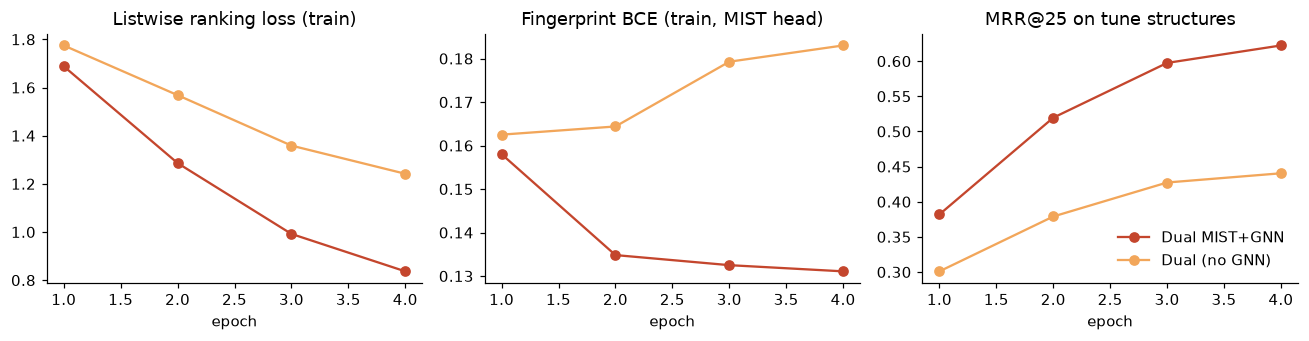

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for h, name in [(hist_dual, "Dual MIST+GNN"), (hist_nog, "Dual (no GNN)")]:
    axes[0].plot(h.epoch, h.rank_loss, "o-", color=COLORS[name], label=name)
    axes[1].plot(h.epoch, h.fp_bce, "o-", color=COLORS[name], label=name)
    axes[2].plot(h.epoch, h.tune_mrr25, "o-", color=COLORS[name], label=name)
axes[0].set(title="Listwise ranking loss (train)", xlabel="epoch")
axes[1].set(title="Fingerprint BCE (train, MIST head)", xlabel="epoch")
axes[2].set(title="MRR@25 on tune structures", xlabel="epoch"); axes[2].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "03_training_curves.png", dpi=200); plt.show()

## 7. Results I — Milton's validation benchmark (per spectrum, full 275k catalog)

In [10]:
log("evaluating Milton's validation spectra")
t0 = time.time()
res = evaluate(dual, test_q, with_baselines=True)
infer_ms = (time.time() - t0) / len(test_q) * 1000
res = res.merge(evaluate(nograph, test_q)[["q"] + [f"Dual (no GNN)_{k}" for k in ["top1", "top5", "mrr25", "rank"]]],
                on="q", how="left")
res["inchikey14"] = queries.inchikey14.values[res.q]
res["adduct"] = queries.adduct.values[res.q]
res["ingest_lib"] = queries.ingest_lib.values[res.q]
table = summarize(res, METHODS)
table["candidate recall"] = res.covered.mean()
res.to_csv(RES / "per_query_test_results.csv", index=False)
table.round(4).to_csv(RES / "summary_test.csv")
print(f"{len(res):,} test spectra; {res.inchikey14.nunique():,} structures; catalog of {cat.N:,} structures")
print("Milton's recap on the same spectra and catalog: Mass only 0.3360, DeepSets likelihood 0.2663 MRR@25")
display(table.round(4))

evaluating Milton's validation spectra


8,068 test spectra; 4,930 structures; catalog of 275,810 structures
Milton's recap on the same spectra and catalog: Mass only 0.3360, DeepSets likelihood 0.2663 MRR@25


,top1,top5,mrr25,candidate recall
Mass only,0.2179,0.4922,0.3436,0.9491
DeepSets FP,0.1613,0.4096,0.2758,0.9491
MIST FP,0.1741,0.4649,0.3045,0.9491
Dual (no GNN),0.3148,0.6510,0.4632,0.9491
Dual MIST+GNN,0.4160,0.7524,0.5599,0.9491


,delta,lo,hi
Dual MIST+GNN − Mass only,0.2163,0.2052,0.2282
Dual MIST+GNN − MIST FP,0.2554,0.2414,0.2693
Dual MIST+GNN − Dual (no GNN),0.0967,0.0867,0.1073
MIST FP − DeepSets FP,0.0287,0.0222,0.0357


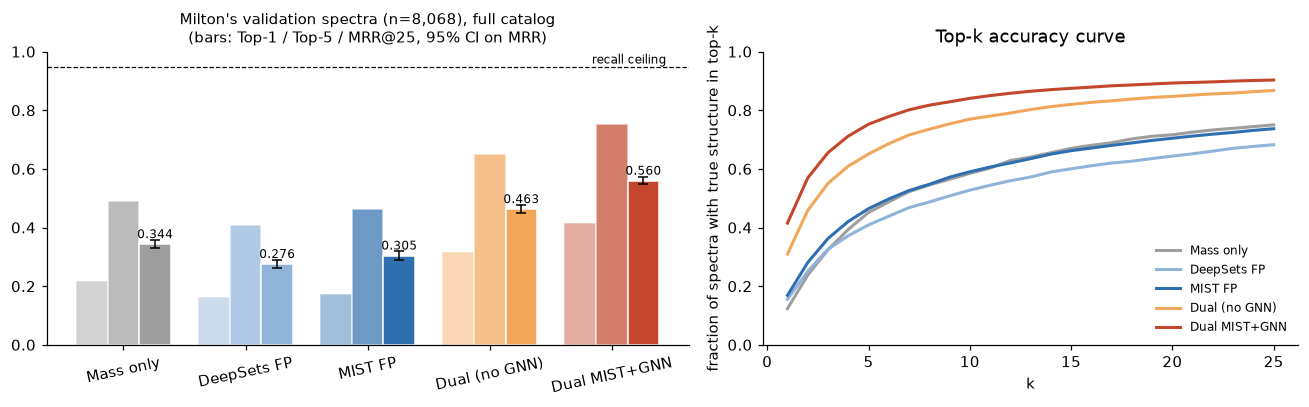

In [11]:
def bootstrap(df, methods, key, pairs, B=1000):
    """95% CIs by resampling whole structures/molecules (spectra of one molecule are not independent)."""
    groups = df.groupby(key).indices; keys = list(groups)
    vals = {m: df[f"{m}_mrr25"].fillna(0).values for m in methods}
    boot = {m: [] for m in methods}; rs = np.random.default_rng(0)
    for _ in range(B):
        idx = np.concatenate([groups[keys[k]] for k in rs.integers(0, len(keys), len(keys))])
        for m in methods:
            boot[m].append(vals[m][idx].mean())
    ci = {m: np.percentile(boot[m], [2.5, 97.5]) for m in methods}
    out = {}
    for a, b_ in pairs:
        d = np.array(boot[a]) - np.array(boot[b_])
        out[f"{a} − {b_}"] = dict(delta=vals[a].mean() - vals[b_].mean(), lo=np.percentile(d, 2.5), hi=np.percentile(d, 97.5))
    return ci, pd.DataFrame(out).T


PAIRS = [("Dual MIST+GNN", "Mass only"), ("Dual MIST+GNN", "MIST FP"), ("Dual MIST+GNN", "Dual (no GNN)"), ("MIST FP", "DeepSets FP")]
ci, paired = bootstrap(res, METHODS, "inchikey14", PAIRS)
display(paired.round(4))
paired.round(4).to_csv(RES / "paired_differences_mrr25.csv")


def results_figure(table, ci, ranks, recall, title, path, unit="spectra"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
    x = np.arange(len(METHODS)); w = 0.26
    for k, met in enumerate(["top1", "top5", "mrr25"]):
        axes[0].bar(x + (k - 1) * w, table.loc[METHODS, met], w, color=[COLORS[m] for m in METHODS],
                    alpha=[0.45, 0.7, 1.0][k], edgecolor="white")
    m_ = table.loc[METHODS, "mrr25"].values
    axes[0].errorbar(x + w, m_, yerr=np.array([[m_[i] - ci[m][0], ci[m][1] - m_[i]] for i, m in enumerate(METHODS)]).T,
                     fmt="none", ecolor="black", capsize=3, lw=1)
    for i, v in enumerate(m_):
        axes[0].text(i + w, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
    axes[0].set_xticks(x, METHODS, rotation=12); axes[0].set_ylim(0, 1)
    axes[0].set_title(f"{title}\n(bars: Top-1 / Top-5 / MRR@25, 95% CI on MRR)", fontsize=10)
    axes[0].axhline(recall, ls="--", color="black", lw=0.8)
    axes[0].text(4.45, recall + 0.01, "recall ceiling", ha="right", fontsize=8)
    ks = np.arange(1, 26)
    for m in METHODS:
        axes[1].plot(ks, [(ranks[m] <= k).mean() for k in ks], color=COLORS[m], lw=2, label=m)
    axes[1].set(xlabel="k", ylabel=f"fraction of {unit} with true structure in top-k", title="Top-k accuracy curve", ylim=(0, 1))
    axes[1].legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()


ranks = {m: res[f"{m}_rank"].where(res.covered, np.inf).fillna(np.inf).values for m in METHODS}
results_figure(table, ci, ranks, res.covered.mean(), f"Milton's validation spectra (n={len(res):,}), full catalog",
               FIG / "04_main_results.png")

### Where does the graph help? Breakdown by isomer ambiguity and source library

,Mass only,DeepSets FP,MIST FP,Dual (no GNN),Dual MIST+GNN,spectra
isomer bucket,,,,,,
1 (unique formula),0.921,0.664,0.696,0.967,0.970,1125
2–3,0.634,0.483,0.515,0.709,0.767,984
4–10,0.373,0.304,0.332,0.508,0.593,1974
11–30,0.176,0.195,0.213,0.356,0.490,1582
31–100,0.065,0.064,0.110,0.229,0.398,1249
>100,0.021,0.021,0.051,0.133,0.309,743


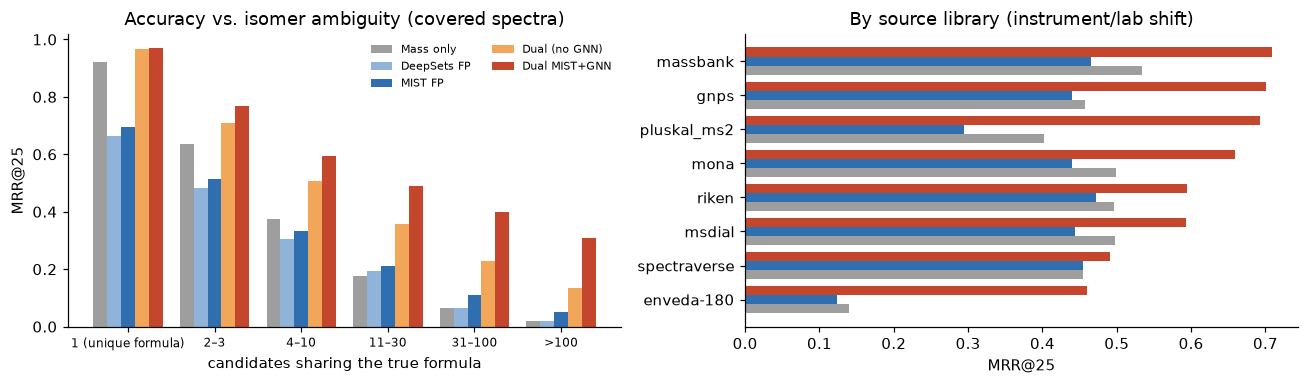

In [12]:
cov = res[res.covered].copy()
cov["isomer bucket"] = pd.cut(cov.isomers, [0, 1, 3, 10, 30, 100, 100_000],
                              labels=["1 (unique formula)", "2–3", "4–10", "11–30", "31–100", ">100"])
by_iso = cov.groupby("isomer bucket", observed=True)[[f"{m}_mrr25" for m in METHODS]].mean()
by_iso.columns = METHODS
by_iso["spectra"] = cov.groupby("isomer bucket", observed=True).size()
display(by_iso.round(3))
by_lib = cov.groupby("ingest_lib")[[f"{m}_mrr25" for m in ["Mass only", "MIST FP", "Dual MIST+GNN"]]].mean()
by_lib.columns = ["Mass only", "MIST FP", "Dual MIST+GNN"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
xb = np.arange(len(by_iso)); w = 0.16
for k, m in enumerate(METHODS):
    axes[0].bar(xb + (k - 2) * w, by_iso[m], w, color=COLORS[m], label=m)
axes[0].set_xticks(xb, by_iso.index, fontsize=8); axes[0].set(xlabel="candidates sharing the true formula", ylabel="MRR@25",
                                                                title="Accuracy vs. isomer ambiguity (covered spectra)")
axes[0].legend(frameon=False, fontsize=7, ncol=2)
by_lib = by_lib.sort_values("Dual MIST+GNN")
yl = np.arange(len(by_lib))
for k, m in enumerate(by_lib.columns):
    axes[1].barh(yl + (k - 1) * 0.27, by_lib[m], 0.27, color=COLORS[m], label=m)
axes[1].set_yticks(yl, by_lib.index); axes[1].set(xlabel="MRR@25", title="By source library (instrument/lab shift)")
fig.tight_layout(); fig.savefig(FIG / "05_breakdown.png", dpi=200); plt.show()

## 8. Results II — natural products on the test instrument (`enveda-np-examples`, per molecule)

Closest available proxy for the hidden Kaggle test set: 250 natural products measured on the same timsTOF and
pipeline, 1–16 spectra per molecule, all structures held out of training. Each molecule ranks **one** pool (10 ppm
around the median neutral mass of its spectra). We compare two protocols:

* **single**: the average score when only one spectrum is used;
* **multi**: all of the molecule's spectra combined by averaging per-spectrum log-softmax scores.

This answers the proposal's central question: does combining spectra measured at several energies or adducts help?

evaluating enveda-np-examples molecules


250 molecules, 1,184 spectra (median 4 per molecule); candidate recall 100.0%; median pool 13
0 of these structures were in the DeepSets checkpoint's training sample.


single spectrum               all spectra (aggregated)         \
                         top1   top5  mrr25                     top1   top5   
Mass only               0.209  0.601  0.380                    0.221  0.608   
DeepSets FP             0.162  0.494  0.315                    0.164  0.486   
MIST FP                 0.181  0.543  0.344                    0.184  0.536   
Dual (no GNN)           0.325  0.762  0.508                    0.328  0.804   
Dual MIST+GNN           0.416  0.819  0.590                    0.452  0.864   

                      
               mrr25  
Mass only      0.392  
DeepSets FP    0.314  
MIST FP        0.345  
Dual (no GNN)  0.522  
Dual MIST+GNN  0.627

,delta,lo,hi
Dual MIST+GNN − Mass only,0.2345,0.1905,0.2773
Dual MIST+GNN − MIST FP,0.2818,0.2302,0.3305
Dual MIST+GNN − Dual (no GNN),0.1041,0.0614,0.1460
Dual MIST+GNN − Dual MIST+GNN_single,0.0364,0.0185,0.0543


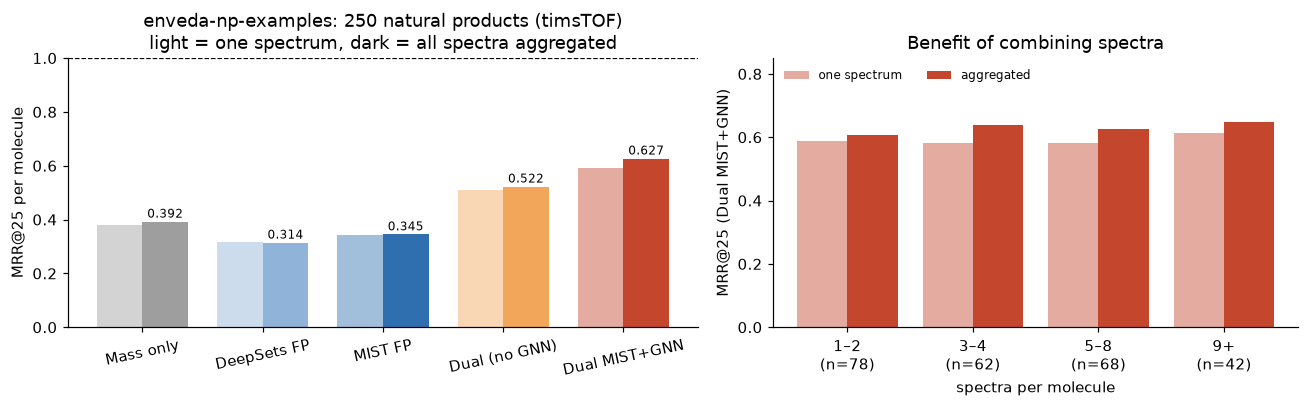

In [13]:
log("evaluating enveda-np-examples molecules")
np_d = evaluate_molecules(dual, np_q, with_baselines=True)
np_n = evaluate_molecules(nograph, np_q)
np_res = np_d.merge(np_n[["molecule"] + [c for c in np_n.columns if c.startswith("Dual (no GNN)")]], on="molecule")
np_res.to_csv(RES / "per_molecule_np_examples.csv", index=False)
multi = summarize(np_res, METHODS)
single = summarize(np_res, [f"{m}_single" for m in METHODS]); single.index = METHODS
np_table = pd.concat({"single spectrum": single, "all spectra (aggregated)": multi}, axis=1)
np_table.round(4).to_csv(RES / "summary_np_examples.csv")
milton_train_ik = set(milton.loc[milton.split == "train", "inchikey14"])
print(f"{len(np_res)} molecules, {np_res.n_spectra.sum():,} spectra (median {np_res.n_spectra.median():.0f} per molecule); "
      f"candidate recall {np_res.covered.mean():.1%}; median pool {np_res.pool.median():.0f}")
print(f"{len(np_ik & milton_train_ik)} of these structures were in the DeepSets checkpoint's training sample.")
display(np_table.round(3))
np_ci, np_paired = bootstrap(np_res, METHODS + ["Dual MIST+GNN_single"], "molecule",
                             PAIRS[:3] + [("Dual MIST+GNN", "Dual MIST+GNN_single")])   # last row: aggregation gain
display(np_paired.round(4))
np_paired.round(4).to_csv(RES / "paired_differences_np_examples.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
x = np.arange(len(METHODS)); w = 0.38
axes[0].bar(x - w / 2, single["mrr25"], w, color=[COLORS[m] for m in METHODS], alpha=0.45, label="one spectrum")
axes[0].bar(x + w / 2, multi["mrr25"], w, color=[COLORS[m] for m in METHODS], label="all spectra aggregated")
for i, (a_, b_) in enumerate(zip(single["mrr25"], multi["mrr25"])):
    axes[0].text(i + w / 2, b_ + 0.015, f"{b_:.3f}", ha="center", fontsize=8)
axes[0].axhline(np_res.covered.mean(), ls="--", color="black", lw=0.8)
axes[0].set_xticks(x, METHODS, rotation=12); axes[0].set_ylim(0, 1)
axes[0].set(ylabel="MRR@25 per molecule", title=f"enveda-np-examples: {len(np_res)} natural products (timsTOF)\n"
                                                 "light = one spectrum, dark = all spectra aggregated")
mm = np_res[np_res.covered]
nb = pd.cut(mm.n_spectra, [0, 2, 4, 8, 100], labels=["1–2", "3–4", "5–8", "9+"])
gain = mm.groupby(nb, observed=True)[["Dual MIST+GNN_single_mrr25", "Dual MIST+GNN_mrr25"]].mean()
gx = np.arange(len(gain))
axes[1].bar(gx - 0.2, gain.iloc[:, 0], 0.4, color=COLORS["Dual MIST+GNN"], alpha=0.45, label="one spectrum")
axes[1].bar(gx + 0.2, gain.iloc[:, 1], 0.4, color=COLORS["Dual MIST+GNN"], label="aggregated")
axes[1].set_xticks(gx, [f"{i}\n(n={c})" for i, c in zip(gain.index, mm.groupby(nb, observed=True).size())])
axes[1].set(xlabel="spectra per molecule", ylabel="MRR@25 (Dual MIST+GNN)", title="Benefit of combining spectra")
axes[1].set_ylim(0, 0.85); axes[1].legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "07_np_examples_multispectrum.png", dpi=200); plt.show()

### Qualitative example: a spectrum where mass alone is ambiguous

Query VTCSXQFTKTVTCF  [M+H]+  pool=25  isomers=12; mass-only expected rank 6.5, dual rank 1


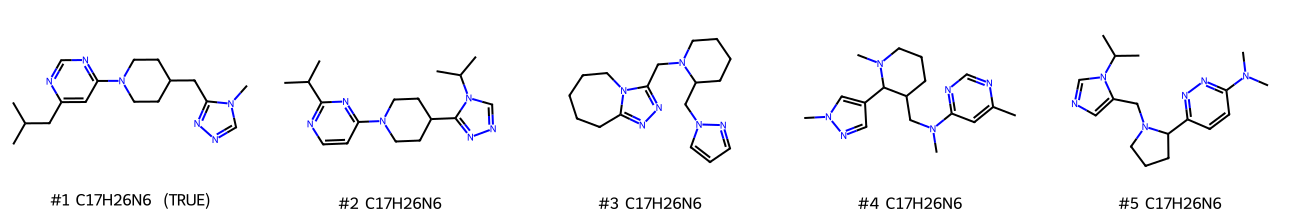

In [14]:
def ranked_pool(q, model):
    p = scorer.own_pool(q)
    return p[np.argsort(-scorer.score_pools(model, [(q, p)], scorer.embed_catalog(model, ids=p))[0][model.name])]


cand = res[(res["Dual MIST+GNN_top1"] == 1) & (res["Mass only_top1"] < 0.2) & (res.isomers.between(4, 12))]
if len(cand):
    q = int(cand.sample(1, random_state=1).q.iloc[0])
    top = ranked_pool(q, dual)[:5]
    true_i = queries.at[q, "cat_idx"]
    mols = [Chem.MolFromSmiles(cat.smiles[i]) for i in top]
    legends = [f"#{r + 1} {cat.formula[i]}" + ("  (TRUE)" if i == true_i else "") for r, i in enumerate(top)]
    rq = res.set_index("q")
    print(f"Query {queries.at[q, 'inchikey14']}  {queries.at[q, 'adduct']}  pool={rq.at[q, 'pool']}  "
          f"isomers={int(rq.at[q, 'isomers'])}; mass-only expected rank {rq.at[q, 'Mass only_rank']:.1f}, dual rank 1")
    img = Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(260, 220), legends=legends)
    img.save(FIG / "06_example_ranking.png") if hasattr(img, "save") else None
    display(img)

## 9. Cost (proposal: report time and memory alongside accuracy)

In [15]:
cost = pd.DataFrame({
    "parameters": [dual.n_params, nograph.n_params, sum(p.numel() for p in deepsets.parameters())],
    "train minutes": [dual.train_minutes, nograph.train_minutes, np.nan],
    "peak GPU GiB (train)": [dual.peak_mem, nograph.peak_mem, np.nan],
}, index=["Dual MIST+GNN", "Dual (no GNN)", "DeepSets FP (Milton)"])
cost.loc["Dual MIST+GNN", "test ms / spectrum (all methods, incl. annotation)"] = infer_ms
display(cost.round(2))
cost.round(3).to_csv(RES / "cost.csv")

,parameters,train minutes,peak GPU GiB (train),"test ms / spectrum (all methods, incl. annotation)"
Dual MIST+GNN,4650976,36.61,1.36,7.3
Dual (no GNN),3249627,20.19,1.13,NaN
DeepSets FP (Milton),354432,NaN,NaN,NaN


## 10. Expanding the candidate catalog with COCONUT

Our first Kaggle submission scored **0.138** public MRR@25, against 0.627 on `enveda-np-examples`. The ranking is not
what fails. Retrieval can only return structures that are in the catalog, and so far the catalog holds only the
275,810 training structures. Kaggle describes the hidden test as a mix of:

* class 1: structures with public spectra;
* class 2: known structures (PubChem / COCONUT) without public spectra;
* class 3: novel structures.

Classes 2 and 3 are never in our catalog. We therefore add **COCONUT** (Chandrasekhar et al., *NAR* 2025), the
open natural-product collection Kaggle names for class 2. The file is the November 2026 lite CSV (CC0), saved in
`data/coconut/` (git-ignored).

Processing:

1. Drop multi-fragment SMILES (salts, mixtures), then keep one structure per InChIKey first block, the identity
   the metric uses.
2. Drop structures already in the training catalog, except the 250 `enveda-np-examples` answers: keeping their
   COCONUT copies lets us measure coverage below.
3. Featurise with the same RDKit code as the training catalog. Keep only formulas inside the model's 13-element
   vocabulary.

The trained model is unchanged. Only the candidate list grows.

In [16]:
COCONUT_ZIP = REPO / "data" / "coconut" / "coconut_csv_lite-11-2026.zip"
EXP_DIR = OUT / "cache" / "catalog_coconut_11-2026"
if (EXP_DIR / "catalog_arrays.npz").exists():
    G_coco = dr.load_catalog(EXP_DIR)
    coco_stats = json.loads((EXP_DIR / "stats.json").read_text())
else:
    t0 = time.time()
    coco = pd.read_csv(COCONUT_ZIP, usecols=["canonical_smiles", "standard_inchi_key"]).dropna()
    coco["ik14"] = coco.standard_inchi_key.str[:14]
    coco_stats = dict(rows=len(coco))
    coco = coco[~coco.canonical_smiles.str.contains(".", regex=False)].drop_duplicates("ik14")
    train_ik = set(G["ik14"])
    coco_stats.update(structures=len(coco), in_training=int(coco.ik14.isin(train_ik).sum()),
                      np_answers=int(coco.ik14.isin(np_ik).sum()))
    coco = coco[~coco.ik14.isin(train_ik - np_ik)]
    G_coco = dr.featurize_catalog(coco.ik14.values, coco.canonical_smiles.values, MODEL_CFG["fp_bits"], CFG["fp_radius"])
    ok = np.array([set(dr.parse_formula(f)) <= set(dr.ELEMS) for f in G_coco["formula"]])
    G_coco = dr.subset_catalog(G_coco, np.where(ok)[0])
    coco_stats.update(featurised=int(ok.size), kept=int(ok.sum()), minutes=round((time.time() - t0) / 60, 1))
    dr.save_catalog(G_coco, EXP_DIR)
    (EXP_DIR / "stats.json").write_text(json.dumps(coco_stats, indent=1))
    G_coco = dr.load_catalog(EXP_DIR)                              # compact dtypes (int16 bonds)
log(f"COCONUT: {coco_stats}")

in_np = np.isin(G_coco["ik14"], list(np_ik))
G_new = dr.subset_catalog(G_coco, np.where(~in_np)[0])            # COCONUT structures not in the training catalog
G_train_wo = dr.subset_catalog(G, np.where(~np.isin(G["ik14"], list(np_ik)))[0])
CATALOGS = {   # built on demand: each full catalog takes a few GB of RAM
    "A. training only": lambda: G,
    "B. training + COCONUT": lambda: dr.concat_catalogs(G, G_new),
    # Kaggle class-2 simulation: the answers are no longer training structures, only COCONUT can supply them
    "C. as B, answers only via COCONUT": lambda: dr.concat_catalogs(G_train_wo, G_coco),
}
print(f"COCONUT lite: {coco_stats['structures']:,} unique structures, {coco_stats['in_training']:,} already in the "
      f"training catalog; {len(G_new['mass']):,} new structures added")
print(f"COCONUT contains {coco_stats['np_answers']} of the {len(np_ik)} enveda-np-examples answers "
      f"({coco_stats['np_answers'] / len(np_ik):.0%})")
display(pd.Series({"A. training only": len(G["mass"]), "B. training + COCONUT": len(G["mass"]) + len(G_new["mass"]),
                    "C. as B, answers only via COCONUT": len(G_train_wo["mass"]) + len(G_coco["mass"])}, name="structures"))

COCONUT: {'rows': 738793, 'structures': 475934, 'in_training': 26111, 'np_answers': 249, 'featurised': 450069, 'kept': 449648, 'minutes': 6.5}


COCONUT lite: 475,934 unique structures, 26,111 already in the training catalog; 449,399 new structures added
COCONUT contains 249 of the 250 enveda-np-examples answers (100%)


A. training only                     275810
B. training + COCONUT                725209
C. as B, answers only via COCONUT    725208
Name: structures, dtype: int64

**Two questions, one experiment.** We re-score the 250 natural products, all spectra aggregated, with three
catalogs:

* **A** is the catalog used so far.
* **B** adds COCONUT. The answer is still present, so the change is the cost of more distractors in each pool.
* **C** removes the answers from the training part. A molecule can then only be found through COCONUT. This
  imitates Kaggle class 2, where the structure has no public spectra.

Only the pools near the 250 molecules are loaded on the GPU (`dr.restrict_catalog`), which leaves every pool
unchanged.

evaluating catalog variants on enveda-np-examples


,recall,median_pool,Mass only MRR@25,Dual MIST+GNN MRR@25,Dual MIST+GNN Top-1
catalog,,,,,
A. training only,1.000,13.0,0.392,0.627,0.452
B. training + COCONUT,1.000,58.0,0.159,0.325,0.160
"C. as B, answers only via COCONUT",0.988,58.0,0.157,0.313,0.148


C, molecules COCONUT can supply (n=247): dual MRR@25 0.317, mass only 0.159


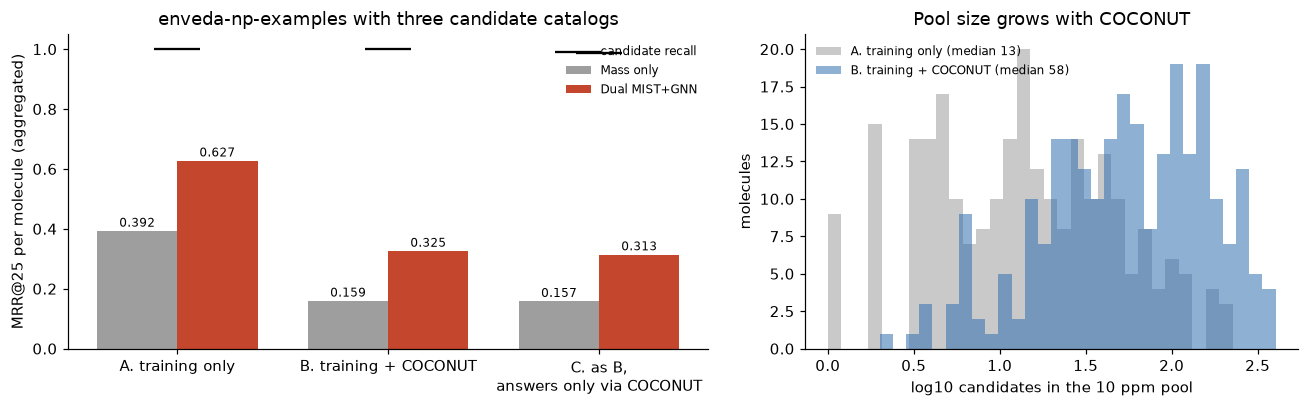

In [17]:
def catalog_eval(G_eval, label, model=dual):
    mols = pd.Series(np_q).groupby(queries.inchikey14.values[np_q]).apply(list)
    c = dr.Catalog(dr.restrict_catalog(G_eval, [np.nanmedian(sp.neutral[mq]) for mq in mols], CFG["ppm"]), DEVICE)
    sc = dr.Scorer(c, sp, CFG["ppm"], CFG["annot_ppm"], CFG["annot_abs"])
    zg = sc.embed_catalog(model)
    rows = []
    for mol, mq in mols.items():
        p, t = sc.molecule_pool(mq), c.index.get(mol)
        r = dict(catalog=label, molecule=mol, pool=len(p), covered=t is not None and bool(np.isin(t, p)))
        if r["covered"]:
            tpos = int(np.where(p == t)[0][0])
            scored = sc.score_pools(model, [(q, p) for q in mq], zg)
            for m in [model.name, "Mass only"]:
                r.update({f"{m}_{k}": v for k, v in dr.tie_metrics(dr.aggregate([d[m] for d in scored]), tpos).items()})
        rows.append(r)
    del c, sc, zg
    return pd.DataFrame(rows)


log("evaluating catalog variants on enveda-np-examples")
cat_res = pd.concat([catalog_eval(make(), k) for k, make in CATALOGS.items()], ignore_index=True)
cat_res.to_csv(RES / "per_molecule_catalog_variants.csv", index=False)
cat_table = cat_res.groupby("catalog", sort=False).agg(
    recall=("covered", "mean"), median_pool=("pool", "median"),
    **{f"{m} MRR@25": (f"{m}_mrr25", lambda x: x.fillna(0).mean()) for m in ["Mass only", "Dual MIST+GNN"]},
    **{"Dual MIST+GNN Top-1": ("Dual MIST+GNN_top1", lambda x: x.fillna(0).mean())})
cat_table.round(4).to_csv(RES / "summary_catalog_variants.csv")
display(cat_table.round(3))
cov = cat_res[cat_res.catalog.str.startswith("C") & cat_res.covered]
print(f"C, molecules COCONUT can supply (n={len(cov)}): dual MRR@25 {cov['Dual MIST+GNN_mrr25'].mean():.3f}, "
      f"mass only {cov['Mass only_mrr25'].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
x = np.arange(len(cat_table)); w = 0.38
for j, (m, off) in enumerate([("Mass only", -w / 2), ("Dual MIST+GNN", w / 2)]):
    v = cat_table[f"{m} MRR@25"].values
    axes[0].bar(x + off, v, w, color=COLORS[m], label=m)
    for i, val in enumerate(v):
        axes[0].text(i + off, val + 0.015, f"{val:.3f}", ha="center", fontsize=8)
axes[0].scatter(x, cat_table.recall, marker="_", s=900, color="black", label="candidate recall", zorder=3)
axes[0].set_xticks(x, [k.replace(", ", ",\n") for k in cat_table.index]); axes[0].set_ylim(0, 1.05)
axes[0].set(ylabel="MRR@25 per molecule (aggregated)", title="enveda-np-examples with three candidate catalogs")
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
for k, col in zip(list(CATALOGS)[:2], ["#9e9e9e", "#2f6fb0"]):
    pools = cat_res.loc[cat_res.catalog == k, "pool"]
    axes[1].hist(np.log10(pools.clip(lower=1)), bins=30, alpha=0.55, color=col, label=f"{k} (median {pools.median():.0f})")
axes[1].set(xlabel="log10 candidates in the 10 ppm pool", ylabel="molecules", title="Pool size grows with COCONUT")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "08_catalog_coconut.png", dpi=200); plt.show()

## 11. Retraining with COCONUT structures as negatives

The model above was trained to reject only training structures, and it never saw a COCONUT structure. On Kaggle,
though, most candidates in a pool now come from COCONUT (section 10). We therefore train the **same model** again:
same spectra, seed, epochs and hyperparameters. Only the candidate catalog changes, to catalog B. A spectrum's hard
negatives (same-formula isomers first, then other formulas from its 10 ppm window) are now drawn from training
structures *and* COCONUT.

* Held-out structures are still excluded from the negatives: Milton's validation set, Antoine's validation hash and
  the 250 natural products.
* The best epoch is chosen on the tune spectra, scored against catalog B.
* Both models are then compared with catalog B on Milton's 8,068 validation spectra, and on the natural products
  with catalogs A, B and C.

In [18]:
def use_catalog(Gx):
    """Point the training/evaluation helpers (globals cat, scorer, TRUE_FID, is_held_out) at catalog Gx."""
    global cat, scorer, TRUE_FID, is_held_out
    cat = scorer = None
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    cat = dr.Catalog(Gx, DEVICE)
    scorer = dr.Scorer(cat, sp, CFG["ppm"], CFG["annot_ppm"], CFG["annot_abs"])
    queries["cat_idx"] = queries.inchikey14.map(cat.index).astype(int)
    TRUE_FID = cat.fid[queries.cat_idx.values]
    is_held_out = np.isin(cat.ik14, list(held_out))


t0 = time.time()
use_catalog(CATALOGS["B. training + COCONUT"]())
from_coco = ~np.isin(cat.ik14, G["ik14"])
rng = np.random.default_rng(CFG["seed"])
TRAIN_LISTS = {q: train_list(q) for q in fit_q}
neg_coco = np.mean([from_coco[l[1:]].mean() for l in TRAIN_LISTS.values() if len(l) > 1])
log(f"catalog B: {cat.N:,} structures; training lists rebuilt, {neg_coco:.0%} of negatives from COCONUT")
TRAIN_PAIRS = scorer.build_pairs([(q, cat.fid[i]) for q, lst in TRAIN_LISTS.items() for i in lst])
print(f"training lists and annotations rebuilt in {time.time() - t0:.0f}s")
dual_cn, hist_cn = train(True, "Dual MIST+GNN (COCONUT negatives)")
COLORS[dual_cn.name] = "#6a3d9a"

catalog B: 725,209 structures; training lists rebuilt, 44% of negatives from COCONUT


training lists and annotations rebuilt in 311s


[Dual MIST+GNN (COCONUT negatives)] epoch 1/4 step 0/3750 (0.0 min)


[Dual MIST+GNN (COCONUT negatives)] epoch 1/4 step 500/3750 (1.2 min)


[Dual MIST+GNN (COCONUT negatives)] epoch 1/4 step 1000/3750 (2.4 min)


[Dual MIST+GNN (COCONUT negatives)] epoch 1/4 step 1500/3750 (3.5 min)


... (25 outputs left out)

[Dual MIST+GNN (COCONUT negatives)] epoch 4/4 step 2500/3750 (33.4 min)


[Dual MIST+GNN (COCONUT negatives)] epoch 4/4 step 3000/3750 (34.6 min)


[Dual MIST+GNN (COCONUT negatives)] epoch 4/4 step 3500/3750 (35.8 min)


[Dual MIST+GNN (COCONUT negatives)] epoch 4/4  rank 0.900  fp 0.1409  tune MRR@25 0.5771  top1 0.4273  (36.6 min)


evaluating both models against catalog B


Tune spectra (n=1,500), catalog B:


,top1,top5,mrr25
Dual MIST+GNN,0.4150,0.7582,0.5646
Dual MIST+GNN (COCONUT negatives),0.4277,0.7817,0.5772


Milton's validation spectra (n=8,068), catalog B, median pool 62:


,top1,top5,mrr25,candidate recall
Mass only,0.1228,0.3123,0.2171,0.9491
Dual MIST+GNN,0.2998,0.5892,0.4298,0.9491
Dual MIST+GNN (COCONUT negatives),0.3196,0.6136,0.4532,0.9491


,delta,lo,hi
Dual MIST+GNN (COCONUT negatives) − Dual MIST+GNN,0.0234,0.0146,0.0310
Dual MIST+GNN (COCONUT negatives) − Mass only,0.2362,0.2253,0.2471
Dual MIST+GNN − Mass only,0.2128,0.2022,0.2236


enveda-np-examples, MRR@25 per molecule (all spectra aggregated):


,Mass only,Dual MIST+GNN,Dual MIST+GNN (COCONUT negatives)
catalog,,,
A. training only,0.392,0.627,0.608
B. training + COCONUT,0.159,0.325,0.348
"C. as B, answers only via COCONUT",0.157,0.313,0.336


Kaggle model (best tune MRR@25 with catalog B): Dual MIST+GNN (COCONUT negatives)


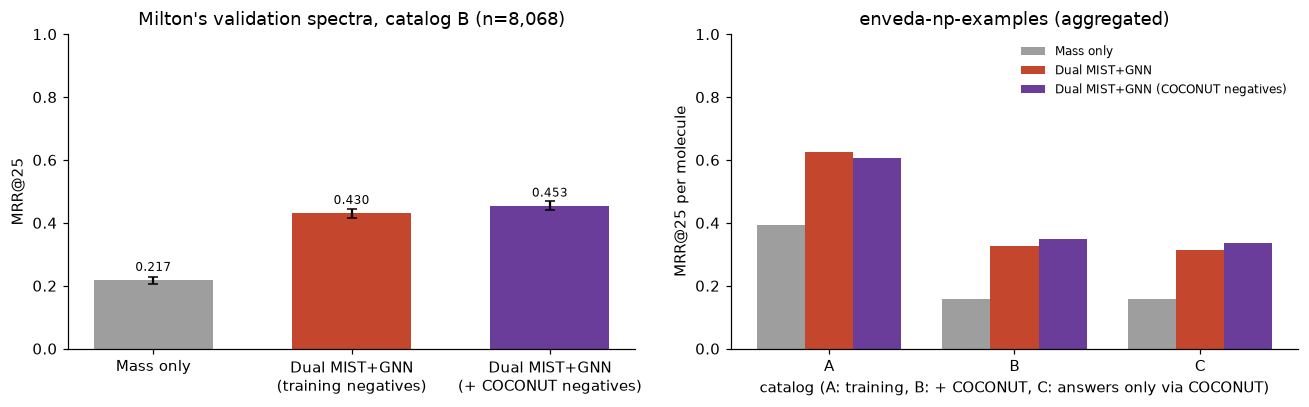

In [19]:
log("evaluating both models against catalog B")
M2 = ["Mass only", "Dual MIST+GNN", dual_cn.name]
cols = lambda m: [f"{m}_{k}" for k in ["top1", "top5", "mrr25", "rank"]]
tune_b = pd.concat([summarize(evaluate(m, tune_q), [m.name]) for m in [dual, dual_cn]])
res_b = evaluate(dual, test_q, with_baselines=True).merge(evaluate(dual_cn, test_q)[["q"] + cols(dual_cn.name)], on="q", how="left")
res_b["inchikey14"] = queries.inchikey14.values[res_b.q]
tab_b = summarize(res_b, M2); tab_b["candidate recall"] = res_b.covered.mean()
ci_b, paired_b = bootstrap(res_b, M2, "inchikey14", [(dual_cn.name, "Dual MIST+GNN"), (dual_cn.name, "Mass only"),
                                                      ("Dual MIST+GNN", "Mass only")])
res_b.to_csv(RES / "per_query_test_results_catalogB.csv", index=False)
tab_b.round(4).to_csv(RES / "summary_test_catalogB.csv"); paired_b.round(4).to_csv(RES / "paired_differences_catalogB.csv")
print(f"Tune spectra (n={len(tune_q):,}), catalog B:"); display(tune_b.round(4))
print(f"Milton's validation spectra (n={len(res_b):,}), catalog B, median pool {res_b.pool.median():.0f}:")
display(tab_b.round(4)); display(paired_b.round(4))

cat_res_cn = pd.concat([catalog_eval(make(), k, dual_cn) for k, make in CATALOGS.items()], ignore_index=True)
cat_cmp = pd.DataFrame({
    "Mass only": cat_res.groupby("catalog", sort=False)["Mass only_mrr25"].apply(lambda x: x.fillna(0).mean()),
    "Dual MIST+GNN": cat_res.groupby("catalog", sort=False)["Dual MIST+GNN_mrr25"].apply(lambda x: x.fillna(0).mean()),
    dual_cn.name: cat_res_cn.groupby("catalog", sort=False)[f"{dual_cn.name}_mrr25"].apply(lambda x: x.fillna(0).mean())})
cat_cmp.round(4).to_csv(RES / "summary_catalog_variants_retrained.csv")
print("enveda-np-examples, MRR@25 per molecule (all spectra aggregated):"); display(cat_cmp.round(3))

KAGGLE_MODEL = dual_cn if tune_b.loc[dual_cn.name, "mrr25"] > tune_b.loc[dual.name, "mrr25"] else dual
log(f"Kaggle model (best tune MRR@25 with catalog B): {KAGGLE_MODEL.name}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(M2))
v = tab_b.loc[M2, "mrr25"].values
axes[0].bar(x, v, 0.6, color=[COLORS[m] for m in M2],
            yerr=np.array([[v[i] - ci_b[m][0], ci_b[m][1] - v[i]] for i, m in enumerate(M2)]).T, capsize=3)
for i, val in enumerate(v):
    axes[0].text(i, val + 0.03, f"{val:.3f}", ha="center", fontsize=8)
axes[0].set_xticks(x, ["Mass only", "Dual MIST+GNN\n(training negatives)", "Dual MIST+GNN\n(+ COCONUT negatives)"])
axes[0].set(ylim=(0, 1), ylabel="MRR@25", title=f"Milton's validation spectra, catalog B (n={len(res_b):,})")
xc = np.arange(len(cat_cmp)); w = 0.26
for k, m in enumerate(cat_cmp.columns):
    axes[1].bar(xc + (k - 1) * w, cat_cmp[m], w, color=COLORS[m], label=m)
axes[1].set_xticks(xc, [i.split(".")[0] for i in cat_cmp.index])
axes[1].set(ylim=(0, 1), xlabel="catalog (A: training, B: + COCONUT, C: answers only via COCONUT)",
            ylabel="MRR@25 per molecule", title="enveda-np-examples (aggregated)")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "09_coconut_negatives.png", dpi=200); plt.show()

## 12. Export the Kaggle inference bundle

CASMI26 is a *code competition*: Kaggle only scores a `submission.csv` written by a notebook that it re-runs offline
on the hidden test set. This cell writes what that notebook needs into `mo_graph/kaggle/bundle/` (git-ignored,
~150 MB):

* the shared module, `dualrerank.py`;
* the featurised catalog B: training structures + COCONUT (section 10);
* the trained weights of the model chosen in section 11;
* a small config file.

Upload the bundle as a private Kaggle Dataset and attach it to
`mo_graph/kaggle/casmi26_dual_reranker_inference.ipynb` (see `mo_graph/kaggle/README.md`).

In [20]:
BUNDLE = OUT / "kaggle" / "bundle"; BUNDLE.mkdir(parents=True, exist_ok=True)
shutil.copy(OUT / "dualrerank.py", BUNDLE / "dualrerank.py")
dr.save_catalog(CATALOGS["B. training + COCONUT"](), BUNDLE)
shutil.copy(CKPT / f"{KAGGLE_MODEL.name.replace(' ', '_')}.pt", BUNDLE / "dual_mist_gnn.pt")   # chosen in section 11
with open(BUNDLE / "config.json", "w") as fh:
    json.dump(dict(model=MODEL_CFG, adduct_vocab=ADDUCT_VOCAB, max_peaks=CFG["max_peaks"], ppm=CFG["ppm"],
                   annot_ppm=CFG["annot_ppm"], annot_abs=CFG["annot_abs"],
                   catalog=f"{len(G['mass'])} training structures + {len(G_new['mass'])} COCONUT 11-2026",
                   weights=KAGGLE_MODEL.name), fh, indent=1)
display(pd.DataFrame([(f.name, f"{f.stat().st_size / 2**20:.1f} MB") for f in sorted(BUNDLE.iterdir())],
                     columns=["file", "size"]))

,file,size
0,catalog_arrays.npz,106.5 MB
1,catalog_meta.parquet,36.2 MB
2,config.json,0.0 MB
3,dataset-metadata.json,0.0 MB
4,dual_mist_gnn.pt,17.8 MB
5,dualrerank.py,0.0 MB


## 13. Take-aways for the report

Run: seed 42; 120,000 training spectra (one per structure, 62% of the structures also measured outside enveda-180);
4 epochs; full catalog of 275,810 structures; 95% CIs from 1,000 bootstrap resamples of whole structures/molecules.

**Milton's validation benchmark** (8,068 spectra, 4,930 held-out structures, full catalog, candidate recall 94.9%)

| Method | Top-1 | Top-5 | MRR@25 |
|---|---:|---:|---:|
| Mass only | 0.218 | 0.492 | 0.344 |
| DeepSets FP (Milton's checkpoint) | 0.161 | 0.410 | 0.276 |
| MIST FP (fingerprint head only) | 0.174 | 0.465 | 0.305 |
| Dual, no GNN (ablation) | 0.315 | 0.651 | 0.463 |
| **Dual MIST + GNN** | **0.416** | **0.753** | **0.560** |

**Natural products on the test instrument** (`enveda-np-examples`: 250 molecules / 1,184 timsTOF spectra, per
molecule, all spectra aggregated)

| Method | MRR@25, one spectrum | MRR@25, aggregated | Top-1, aggregated |
|---|---:|---:|---:|
| Mass only | 0.380 | 0.392 | 0.221 |
| DeepSets FP | 0.315 | 0.314 | 0.164 |
| MIST FP | 0.344 | 0.345 | 0.184 |
| Dual, no GNN | 0.508 | 0.522 | 0.328 |
| **Dual MIST + GNN** | **0.590** | **0.627** | **0.452** |

* **Pipeline sanity check.** Our mass-only and DeepSets baselines (0.344 / 0.276) reproduce Milton's full-catalog
  numbers (0.336 / 0.266). The small gaps come from the generic adduct parser covering more adducts.
* **The dual model roughly doubles Top-1 over mass alone.**
  - Milton's benchmark: +0.216 MRR@25 [0.205, 0.228].
  - Natural products: +0.235 [0.191, 0.277].
  - It is the first team model to beat mass-only ranking on the full catalog.
* **The GNN carries the isomer problem.** With the spectrum encoder and all other inputs fixed, the graph branch adds
  +0.097 [0.087, 0.107] on Milton's benchmark and +0.104 [0.061, 0.146] on the natural products. The gain grows with
  ambiguity: for more than 100 same-formula candidates, MRR@25 goes from 0.13 without the GNN to 0.31 with it, versus
  0.02 for mass alone.
* **MIST encodes spectra better than DeepSets** (+0.029 [0.022, 0.036] as a fingerprint retriever). On its own,
  though, fingerprint retrieval still loses to mass. The value comes from combining formula-annotated spectra,
  molecular graphs and mass error in one learned scorer.
* **Multiple spectra help (the proposal's central question).** Averaging per-spectrum log-softmax scores over a
  molecule's spectra adds +0.036 [0.019, 0.054] MRR@25 for the dual model. The gain is largest for molecules with
  3+ spectra.
* **Cost.** The model has 4.7M parameters. Training takes 37 min at 1.4 GiB peak GPU memory on a 4 GB RTX 3050 Ti,
  and scoring takes about 10 ms per spectrum (full catalog, all baselines included).

  Windows note: the NVIDIA driver silently spills CUDA memory into system RAM, which made the first full run about 8×
  slower. Capping the process memory fraction fixed it.
* **Limitations.**
  - Retrieval cannot find Kaggle's class-3 (novel) structures; that needs the team's de novo generator.
  - Candidate recall caps MRR@25 at 0.95.
  - One seed only, and 120k of the 270k available training structures (compute budget).
  - Tune MRR was still rising at epoch 4.
  - `enveda-180` (synthetic, timsTOF) is still the hardest library.
  - A scored Kaggle entry must run as an offline Kaggle notebook. `mo_graph/kaggle/` contains it, and section 12
    exports its inputs.


**Candidate catalog and Kaggle** (section 10)

| Catalog (`enveda-np-examples`, aggregated) | Recall | Median pool | Mass only MRR@25 | Dual MRR@25 |
|---|---:|---:|---:|---:|
| A. training structures (275,810) | 1.000 | 13 | 0.392 | 0.627 |
| B. + COCONUT (725,209) | 1.000 | 58 | 0.159 | 0.325 |
| C. as B, answers only via COCONUT | 0.988 | 58 | 0.157 | 0.313 |

* COCONUT contains 249 of the 250 natural-product answers. A known natural product without public spectra (Kaggle
  class 2) goes from unfindable to MRR@25 0.31 (catalog C).
* The price is about 4× more candidates per pool. With the answer present, the dual model drops from 0.627 to 0.325,
  but still doubles mass alone (0.159).
* **Kaggle public MRR@25: 0.138 with catalog A, 0.192 with catalog B.** The hidden test therefore contains many
  molecules that only COCONUT supplies.

**Retraining with COCONUT negatives** (section 11; same seed, data and epochs; 44% of negatives from COCONUT)

| MRR@25 | Mass only | Dual (training negatives) | Dual (+ COCONUT negatives) |
|---|---:|---:|---:|
| Milton's 8,068 spectra, catalog B | 0.217 | 0.430 | **0.453** |
| Natural products, catalog A | 0.392 | **0.627** | 0.608 |
| Natural products, catalog B | 0.159 | 0.325 | **0.348** |
| Natural products, catalog C | 0.157 | 0.313 | **0.336** |

* +0.023 [0.015, 0.031] on Milton's benchmark with catalog B. The model is chosen by tune MRR@25 and exported.
* **Kaggle public MRR@25: 0.190**, a tie with 0.192 (the public split scores only part of the ~400 molecules). The
  remaining gap to the leaderboard top (~0.55) is most likely coverage beyond COCONUT (PubChem) and novel structures.

**References.** Goldman et al., *MIST*, Nat. Mach. Intell. 5, 965 (2023) · Kalia et al., *JESTR*, Bioinformatics
btaf354 (2025) · Bushuiev et al., *MassSpecGym*, NeurIPS D&B (2024) · Dührkop et al., *CSI:FingerID*, PNAS (2015) ·
Xu et al., *GIN*, ICLR (2019) · Hu et al., *Strategies for pre-training GNNs* (GINE), ICLR (2020) · Zaheer et al.,
*Deep Sets*, NeurIPS (2017) · Gilmer et al., *MPNN*, ICML (2017).